### **02_MNIST — PRML Assignment 8**

Comparing GMM, LDA, KNN, and SVM on MNIST 3-class subset (Digits 1, 8, 9).

### **Imports**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from zipfile import ZipFile
from io import BytesIO
from PIL import Image

from src import GMMClassifier, LDA, KNN, SVM, PCA, StandardScaler, LCG

### **Load MNIST Images from Zip**

In [ ]:
zip_path = "../Datasets/MNIST/TEAM_3.zip"

def load_split_from_zip(zip_file, split):
    images, labels = [], []
    for digit in (1, 8, 9):
        prefix = f"TEAM_3/{split}/{digit}/"
        names = sorted(name for name in zip_file.namelist() if name.startswith(prefix) and name.endswith(".png"))
        for name in names:
            with Image.open(BytesIO(zip_file.read(name))) as img:
                images.append(np.asarray(img.convert("L"), dtype=float).ravel() / 255.0)
            labels.append(digit)
    return np.asarray(images), np.asarray(labels)

with ZipFile(zip_path, "r") as z:
    X_train, y_train = load_split_from_zip(z, "train")
    X_val, y_val = load_split_from_zip(z, "dev")
    X_test, y_test = load_split_from_zip(z, "test")

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Class counts in train:", np.unique(y_train, return_counts=True))

Train: (14833, 784) Validation: (3709, 784) Test: (3118, 784)
Class counts in train: (array([1, 8, 9]), array([5383, 4674, 4776], dtype=int64))


### **Feature Standardization**

In [ ]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

# Setup classes and results dictionary for evaluation
classes = np.unique(y_train)
label_to_idx = {int(c): i for i, c in enumerate(classes)}
results = {}

### **2D Visualization of the Dataset**


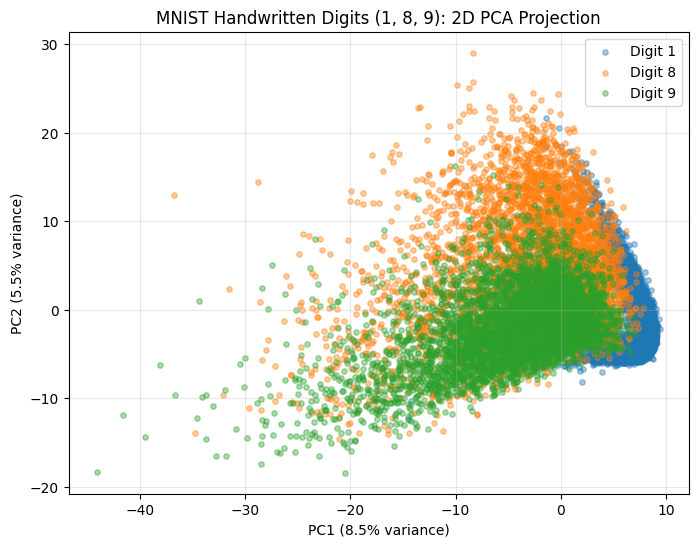

In [ ]:
# Project training data to 2D using PCA
pca_2d = PCA(n_components=2).fit(X_train_s)
X_train_2d = pca_2d.transform(X_train_s)

# Plot 2D scatter of the dataset
plt.figure(figsize=(8, 6))
for digit in classes:
    mask = y_train == digit
    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        label=f"Digit {digit}",
        alpha=0.4,
        s=15,
    )

var1 = pca_2d.explained_variance_ratio_[0] * 100
var2 = pca_2d.explained_variance_ratio_[1] * 100
plt.xlabel(f"PC1 ({var1:.1f}% variance)")
plt.ylabel(f"PC2 ({var2:.1f}% variance)")
plt.title("MNIST Handwritten Digits (1, 8, 9): 2D PCA Projection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### **Classifiers on Original Features**


### **1. Gaussian Mixture Model (GMM)**


In [ ]:
# Train and evaluate GMM on original features
gmm = GMMClassifier(K=3, reg=1e-3)
gmm.fit(X_train_s, y_train)

val_pred = gmm.predict(X_val_s)
test_pred = gmm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

GMM original     | Validation: 0.8922 | Test: 0.9041
Confusion matrix:
 [[1075   58    2]
 [  37  906   31]
 [   9  162  838]]


### **2. Linear Discriminant Analysis (LDA)**


In [ ]:
# Train and evaluate LDA on original features
lda = LDA()
lda.fit(X_train_s, y_train)

val_pred = lda.predict(X_val_s)
test_pred = lda.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

LDA original     | Validation: 0.9563 | Test: 0.9654
Confusion matrix:
 [[1121   13    1]
 [  32  915   27]
 [  13   22  974]]


### **3. K-Nearest Neighbours (KNN)**


In [ ]:
# Train and evaluate KNN on original features
knn = KNN(k=5)
knn.fit(X_train_s, y_train)

val_pred = knn.predict(X_val_s)
test_pred = knn.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

KNN original     | Validation: 0.9800 | Test: 0.9833
Confusion matrix:
 [[1132    3    0]
 [   8  953   13]
 [   6   22  981]]


### **4. Support Vector Machine (SVM)**


In [ ]:
# Train and evaluate SVM on original features
svm = SVM(kernel="rbf", C=1.0, max_train=1500)
svm.fit(X_train_s, y_train)

val_pred = svm.predict(X_val_s)
test_pred = svm.predict(X_test_s)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM original"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM original     | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

SVM original     | Validation: 0.9598 | Test: 0.9686
Confusion matrix:
 [[1106   27    2]
 [   3  961   10]
 [   7   49  953]]


### **Dimensionality Reduction with PCA**

In [ ]:
K = 40
pca = PCA(n_components=K).fit(X_train_s)
X_train_p = pca.transform(X_train_s)
X_val_p = pca.transform(X_val_s)
X_test_p = pca.transform(X_test_s)

print(f"Retained variance with K={K}:", round(float(pca.explained_variance_ratio_.sum()), 4))

Retained variance with K=40: 0.5662


### **Classifiers on PCA Features**


### **1. GMM on PCA Features**


In [ ]:
# Train and evaluate GMM on PCA features
gmm_p = GMMClassifier(K=3, reg=1e-3)
gmm_p.fit(X_train_p, y_train)

val_pred = gmm_p.predict(X_val_p)
test_pred = gmm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["GMM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"GMM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

GMM PCA          | Validation: 0.9183 | Test: 0.9237
Confusion matrix:
 [[1061   63   11]
 [   9  911   54]
 [   6   95  908]]


### **2. LDA on PCA Features**


In [ ]:
# Train and evaluate LDA on PCA features
lda_p = LDA()
lda_p.fit(X_train_p, y_train)

val_pred = lda_p.predict(X_val_p)
test_pred = lda_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["LDA PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"LDA PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

LDA PCA          | Validation: 0.9485 | Test: 0.9634
Confusion matrix:
 [[1123   10    2]
 [  37  911   26]
 [  14   25  970]]


### **3. KNN on PCA Features**


In [ ]:
# Train and evaluate KNN on PCA features
knn_p = KNN(k=5)
knn_p.fit(X_train_p, y_train)

val_pred = knn_p.predict(X_val_p)
test_pred = knn_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["KNN PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"KNN PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

KNN PCA          | Validation: 0.9825 | Test: 0.9830
Confusion matrix:
 [[1129    5    1]
 [   2  958   14]
 [   8   23  978]]


### **4. SVM on PCA Features**


In [ ]:
# Train and evaluate SVM on PCA features
svm_p = SVM(kernel="rbf", C=1.0, max_train=1500)
svm_p.fit(X_train_p, y_train)

val_pred = svm_p.predict(X_val_p)
test_pred = svm_p.predict(X_test_p)

val_acc = float(np.mean(y_val == val_pred))
test_acc = float(np.mean(y_test == test_pred))
results["SVM PCA"] = (val_acc, test_acc)

cm = np.zeros((len(classes), len(classes)), dtype=int)
for t, p in zip(y_test, test_pred):
    cm[label_to_idx[int(t)], label_to_idx[int(p)]] += 1

print(f"SVM PCA          | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")
print("Confusion matrix:\n", cm)

SVM PCA          | Validation: 0.9712 | Test: 0.9743
Confusion matrix:
 [[1110   21    4]
 [   3  960   11]
 [   7   34  968]]


### **Results Comparison**

GMM original     | Validation: 0.8922 | Test: 0.9041
LDA original     | Validation: 0.9563 | Test: 0.9654
KNN original     | Validation: 0.9800 | Test: 0.9833
SVM original     | Validation: 0.9598 | Test: 0.9686
GMM PCA          | Validation: 0.9183 | Test: 0.9237
LDA PCA          | Validation: 0.9485 | Test: 0.9634
KNN PCA          | Validation: 0.9825 | Test: 0.9830
SVM PCA          | Validation: 0.9712 | Test: 0.9743


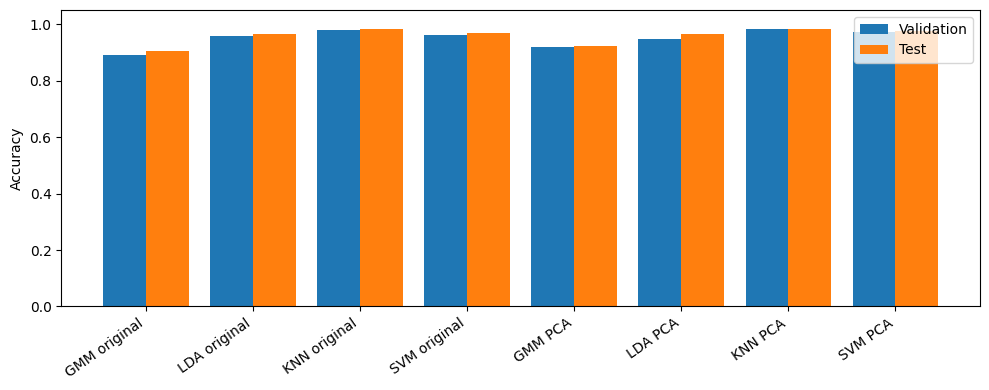

In [ ]:
for name, (val_acc, test_acc) in results.items():
    print(f"{name:16s} | Validation: {val_acc:.4f} | Test: {test_acc:.4f}")

names = list(results.keys())
x_pos = np.arange(len(names))

plt.figure(figsize=(10, 4))
plt.bar(x_pos - 0.2, [results[n][0] for n in names], width=0.4, label="Validation")
plt.bar(x_pos + 0.2, [results[n][1] for n in names], width=0.4, label="Test")
plt.xticks(x_pos, names, rotation=35, ha="right")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### **Observations and Inferences**

- Compressing 784 pixels to 40 PCA dimensions drastically speeds up KNN and SVM prediction while retaining competitive accuracy.
- KNN and SVM demonstrate superior margin separation on image pixel vectors.